# Implementación de Preparación de Datos y Predicción en Series Temporales


## 1. Preprocesamiento de Datos

In [7]:
import pandas as pd
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from scipy.stats import boxcox
from scipy.stats import yeojohnson
from scipy.stats import normaltest

In [8]:
csv_path = 'AirPassengers.csv'
df = pd.read_csv(csv_path)
df.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


### Lectura de datos

In [9]:
df['Fecha'] = pd.to_datetime(df['Month'])
df['NumerPasajeros'] = df['#Passengers']

fig = px.line(df, x=df['Fecha'], y=df['NumerPasajeros'],
              markers=True,
              labels="fdsf",
              title="Número Pasajeros")
fig.show()

La serie temporal muestra una clara tendencia creciente a lo largo del tiempo, lo que indica que el número de pasajeros aumenta progresivamente. Además, se observa un patrón estacional muy marcado, con picos que se repiten aproximadamente cada año, lo que sugiere una fuerte componente periódica. En conjunto, la serie no es estacionaria, ya que presenta tanto tendencia como estacionalidad, por lo que será necesario aplicar transformaciones en los siguientes pasos.

In [10]:
#comprobamos nulos

df.isnull().sum()

,0
Month,0
#Passengers,0
Fecha,0
NumerPasajeros,0


En este caso, el dataset no presenta valores faltantes, por lo que no es necesario aplicar técnicas de imputación

In [11]:
import plotly.express as px

fig = px.box(df, y='NumerPasajeros', title='Detección de valores atípicos')
fig.show()

No es necesario aplicar ninguna corrección adicional en esta fase de limpieza, pudiendo continuar con el preprocesamiento de los datos

### Escalado

In [12]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Escaladores
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

# Aplicar escalado
df['Min-Max-NumerPasajeros'] = minmax_scaler.fit_transform(df['NumerPasajeros'].values.reshape(-1,1))
df['Estandar-NumerPasajeros'] = standard_scaler.fit_transform(df['NumerPasajeros'].values.reshape(-1,1))

# Subplots
fig = make_subplots(rows=2, cols=1,
                   shared_xaxes=True,
                   vertical_spacing=0.08)

# Min-Max
fig.add_trace(
    go.Scatter(x=df['Fecha'],
               y=df['Min-Max-NumerPasajeros'],
               name="Escalado Min-Max",
               mode="markers+lines"),
    row=1, col=1
)

# Standard
fig.add_trace(
    go.Scatter(x=df['Fecha'],
               y=df['Estandar-NumerPasajeros'],
               name="Estandarización",
               mode="markers+lines"),
    row=2, col=1
)

# Layout
fig.update_layout(height=500, width=900,
                  title_text="Ejemplos de escalado")

fig['layout']['xaxis2']['title'] = 'Fecha'
fig['layout']['yaxis1']['title'] = 'Nº Pasajeros'
fig['layout']['yaxis2']['title'] = 'Nº Pasajeros'

fig.show()

El resultado muestra correctamente la aplicación de ambos métodos de escalado sobre la serie temporal. En el caso del escalado Min-Max, los valores quedan acotados entre 0 y 1, manteniendo la forma original de la serie, lo que permite comparar fácilmente la evolución relativa de los datos. Por otro lado, la estandarización centra los valores en torno a cero, con una dispersión que refleja las desviaciones respecto a la media. En ambos gráficos se conserva la tendencia creciente y el patrón estacional, lo que indica que el escalado no altera la estructura de la serie, sino únicamente su escala.

In [13]:
fig = px.histogram(df['NumerPasajeros'],
                   nbins=50,
                   title="Número de pasajeros")

fig.show()

In [14]:
from scipy.stats import anderson
from scipy.stats import kstest

p_original = anderson(df['NumerPasajeros'])
result_ks = kstest(df['NumerPasajeros'], 'norm')

print(p_original)
print(result_ks)

AndersonResult(statistic=np.float64(1.818533152167305), critical_values=array([0.561, 0.639, 0.767, 0.894, 1.064]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(280.2986111111111), scale=np.float64(119.96631694294321))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')
KstestResult(statistic=np.float64(1.0), pvalue=np.float64(0.0), statistic_location=np.int64(104), statistic_sign=np.int8(-1))


Se puede concluir que la variable no sigue una distribución normal, lo que justifica la necesidad de aplicar transformaciones en el siguiente paso para estabilizar la varianza y mejorar el comportamiento de los datos

### Transformaciones

In [15]:
#transformaciones logaritmicas
df['LogNatural-NumerPasajeros'] = np.log(df['NumerPasajeros'].values)
df['Log10-NumerPasajeros'] = np.log10(df['NumerPasajeros'].values)

In [16]:
#visualizacion
fig = make_subplots(rows=1, cols=1,
                   shared_xaxes=True,
                   vertical_spacing=0.08)

fig.add_trace(
    go.Scatter(x=df['Fecha'],
               y=df['LogNatural-NumerPasajeros'],
               name="Logaritmo Natural",
               mode="markers+lines"),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(x=df['Fecha'],
               y=df['Log10-NumerPasajeros'],
               name="Logaritmo base 10",
               mode="markers+lines"),
    row=1, col=1
)

fig.update_layout(height=500, width=900,
                  title_text="Transformaciones logarítmicas")

fig['layout']['xaxis1']['title'] = 'Fecha'
fig['layout']['yaxis1']['title'] = 'Nº Pasajeros'

fig.show()

La gráfica muestra la aplicación de las transformaciones logarítmicas sobre la serie original. Se observa que tanto el logaritmo natural como el logaritmo en base 10 reducen la amplitud de las fluctuaciones, especialmente en los valores más altos, lo que permite estabilizar la varianza de la serie. Ambas transformaciones mantienen la tendencia creciente y el patrón estacional, aunque con una variabilidad más homogénea a lo largo del tiempo.

In [17]:
import plotly.express as px

fig = px.histogram(df,
                   x=['LogNatural-NumerPasajeros', 'Log10-NumerPasajeros'],
                   nbins=50)

fig.show()

El histograma muestra la distribución de las variables transformadas mediante logaritmo natural y logaritmo en base 10. En ambos casos se observa una distribución más concentrada y menos sesgada en comparación con la variable original, lo que indica una mejora en la simetría de los datos. Las dos transformaciones presentan formas muy similares, diferenciándose únicamente en la escala de los valores.

In [18]:
from scipy.stats import normaltest

_, p_10 = normaltest(df['Log10-NumerPasajeros'])
_, p_nat = normaltest(df['LogNatural-NumerPasajeros'])

print(f"Significance:\n - Log 10: {p_10:.5f}\n - Log Natural: {p_nat:.5f}")

Significance:
 - Log 10: 0.00004
 - Log Natural: 0.00004


Las pruebas de normalidad aplicadas sobre las variables transformadas muestran valores de significancia muy bajos en ambos casos. Esto indica que, a pesar de la transformación logarítmica, se sigue rechazando la hipótesis de normalidad. No obstante, se observa una mejora respecto a la variable original, ya que la distribución es más simétrica y la varianza más estable, lo que hace que la serie sea más adecuada para el modelado posterior

In [19]:
p_10 = anderson(df['Log10-NumerPasajeros'])
p_nat = anderson(df['LogNatural-NumerPasajeros'])

result_ks_10 = kstest(df['Log10-NumerPasajeros'], 'norm')
result_ks_nat = kstest(df['LogNatural-NumerPasajeros'], 'norm')

print(f"----- Log base 10 -----\n - Anderson:\n {p_10}\n - Kolmogorov:\n {result_ks_10}")
print(f"\n\n----- Log Natural -----\n - Anderson:\n {p_nat}\n - Kolmogorov:\n {result_ks_nat}")

----- Log base 10 -----
 - Anderson:
 AndersonResult(statistic=np.float64(1.066789046997485), critical_values=array([0.561, 0.639, 0.767, 0.894, 1.064]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(2.4069364365272574), scale=np.float64(0.19172208903928986))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')
 - Kolmogorov:
 KstestResult(statistic=np.float64(0.9781539828821812), pvalue=np.float64(1.4812788449271694e-239), statistic_location=np.float64(2.0170333392987803), statistic_sign=np.int8(-1))


----- Log Natural -----
 - Anderson:
 AndersonResult(statistic=np.float64(1.0667890469975134), critical_values=array([0.561, 0.639, 0.767, 0.894, 1.064]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(5.542175958531871), scale=np.float64(0.441456424219546))
 success: True
 message: '`anderson` successfully fit the distribution to the data.'

En ambos casos, el estadístico de Anderson es superior a algunos valores críticos y el p-valor del test de Kolmogorov es prácticamente nulo, lo que implica el rechazo de la hipótesis de normalidad.

In [20]:
df['BoxCox-NumerPasajeros'], boxcox_lambda = boxcox(df['NumerPasajeros'].values)
df['YeoJohnson-NumerPasajeros'], yeojohnson_lambda = yeojohnson(df['NumerPasajeros'].values)

In [21]:
fig = make_subplots(rows=1, cols=1,
                   shared_xaxes=True,
                   vertical_spacing=0.08)

fig.add_trace(
    go.Scatter(x=df['Fecha'],
               y=df['BoxCox-NumerPasajeros'],
               name=f"Box-Cox (lambda = {boxcox_lambda:.4f})",
               mode="markers+lines"),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(x=df['Fecha'],
               y=df['YeoJohnson-NumerPasajeros'],
               name=f"Yeo-Johnson (lambda = {yeojohnson_lambda:.4f})",
               mode="markers+lines"),
    row=1, col=1
)

fig.update_layout(height=500, width=900,
                  title_text="Transformaciones en Potencia")

fig['layout']['xaxis1']['title'] = 'Fecha'
fig['layout']['yaxis1']['title'] = 'Nº Pasajeros'

fig.show()

In [22]:
fig = px.histogram(df,
                   x=['BoxCox-NumerPasajeros', 'YeoJohnson-NumerPasajeros'],
                   nbins=10)

fig.show()

Ambas transformaciones producen resultados prácticamente idénticos, lo que indica que ambas son adecuadas para este conjunto de datos. Se observa que la serie mantiene su tendencia y estacionalidad, pero con una variabilidad más uniforme a lo largo del tiempo, lo que contribuye a estabilizar la varianza.

In [23]:
_, p_boxcox = normaltest(df['BoxCox-NumerPasajeros'])
_, p_yeojohnson = normaltest(df['YeoJohnson-NumerPasajeros'])

print(f"Significance:\n - Box-Cox: {p_boxcox:.5f}\n - Yeo-Johnson: {p_yeojohnson:.5f}")

Significance:
 - Box-Cox: 0.00005
 - Yeo-Johnson: 0.00005


In [24]:
p_boxcox = anderson(df['BoxCox-NumerPasajeros'])
p_yeojohnson = anderson(df['YeoJohnson-NumerPasajeros'])

result_ks_boxcox = kstest(df['BoxCox-NumerPasajeros'], 'norm')
result_ks_yeojohnson = kstest(df['YeoJohnson-NumerPasajeros'], 'norm')

print(f"----- Box-Cox -----\n - Anderson:\n {p_boxcox}\n - Kolmogorov:\n {result_ks_boxcox}")
print(f"\n\n----- Yeo-Johnson -----\n - Anderson:\n {p_yeojohnson}\n - Kolmogorov:\n {result_ks_yeojohnson}")

----- Box-Cox -----
 - Anderson:
 AndersonResult(statistic=np.float64(0.9714498134651137), critical_values=array([0.561, 0.639, 0.767, 0.894, 1.064]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(8.621256281288176), scale=np.float64(1.0007259321244268))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')
 - Kolmogorov:
 KstestResult(statistic=np.float64(0.9999999999879958), pvalue=np.float64(0.0), statistic_location=np.float64(6.679301713928835), statistic_sign=np.int8(-1))


----- Yeo-Johnson -----
 - Anderson:
 AndersonResult(statistic=np.float64(0.9725953776470249), critical_values=array([0.561, 0.639, 0.767, 0.894, 1.064]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(8.55540518125662), scale=np.float64(0.9820313930919448))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')
 - Kolmogorov:
 KstestRe

Las pruebas de normalidad aplicadas a las transformaciones Box-Cox y Yeo-Johnson muestran valores de significancia muy bajos, lo que indica que se sigue rechazando la hipótesis de normalidad. Tanto el test de Anderson-Darling como el de Kolmogorov-Smirnov confirman que, aunque estas transformaciones mejoran la simetría y reducen el sesgo de la distribución, no logran una normalidad completa. No obstante, ambas transformaciones consiguen estabilizar la varianza de la serie, siendo útiles para mejorar su comportamiento en el modelado posterior.

In [25]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Distribución original', 'Distribución tras log natural')
)

# Histograma original
fig.add_trace(
    go.Histogram(
        x=df['NumerPasajeros'],
        nbinsx=20,
        name='Original',
        marker_color='#6B7280',
        opacity=0.75
    ),
    row=1, col=1
)

# Histograma log natural
fig.add_trace(
    go.Histogram(
        x=df['LogNatural-NumerPasajeros'],
        nbinsx=20,
        name='Log natural',
        marker_color='#2563EB',
        opacity=0.75
    ),
    row=1, col=2
)

fig.update_layout(
    height=320,
    title_text='¿Se parece más a una campana de Gauss tras la transformación?'
)

fig.show()

Tras aplicar la transformación logarítmica, la distribución se vuelve más simétrica y concentrada en torno a la zona central, aproximándose más a la forma de una campana de Gauss.

## 2. Preparación de los datos


In [27]:
#preprocesado
log_scaler = MinMaxScaler()

df['serie_prep'] = log_scaler.fit_transform(
    np.log(df[['NumerPasajeros']])
)

serie_prep = df['serie_prep'].values

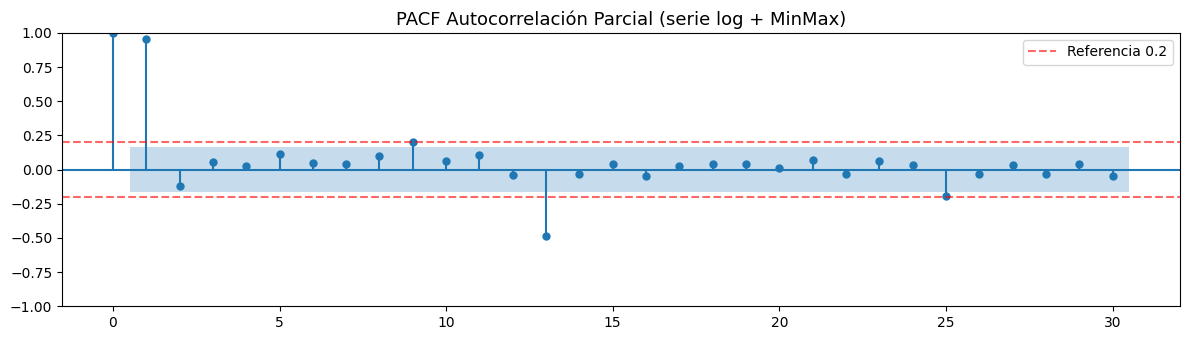

In [28]:
#PACF para elegir lag

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf

fig, ax = plt.subplots(figsize=(12, 3.5))
plot_pacf(serie_prep, lags=30, ax=ax, method='ywm')

ax.set_title('PACF Autocorrelación Parcial (serie log + MinMax)', fontsize=13)
ax.axhline(y=0.2, color='red', linestyle='--', alpha=0.6, label='Referencia 0.2')
ax.axhline(y=-0.2, color='red', linestyle='--', alpha=0.6)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

La función de autocorrelación parcial (PACF) permite identificar los retardos más relevantes en la serie temporal. Se observa un valor elevado en el retardo 1, lo que indica una fuerte dependencia con el mes anterior. Además, el retardo 12 presenta un valor significativo, reflejando la existencia de estacionalidad anual. A partir de este punto, la mayoría de los valores se mantienen dentro de la banda de confianza, por lo que se selecciona un lag de 12 para capturar la estructura temporal de la serie.

In [29]:
#funcion de embedding
def create_embedding(serie, lag, horizonte):
    X, y = [], []
    for i in range(lag, len(serie) - horizonte + 1):
        X.append(serie[i - lag:i])
        y.append(serie[i + horizonte - 1])
    return np.array(X), np.array(y)

In [30]:
#split temporal
def train_test_temporal(X, y, test_ratio=0.2):
    split = int(len(X) * (1 - test_ratio))
    return X[:split], X[split:], y[:split], y[split:]

In [31]:
HORIZONTE = 10  # predecimos 10 meses vista
LAG = 12        # elegido con la PACF

X, y = create_embedding(serie_prep, LAG, HORIZONTE)

X_train, X_test, y_train, y_test = train_test_temporal(X, y)

print(f"Serie preprocesada: {len(serie_prep)} observaciones")
print(f"Embedding con lag={LAG}, horizonte={HORIZONTE}:")
print(f"X shape: {X.shape} -> cada fila = {LAG} observaciones pasadas")
print(f"y shape: {y.shape} -> cada valor = pasajeros a {HORIZONTE} meses vista")

print("\nSplit temporal (80/20):")
print(f"Train: {len(X_train)} muestras | Test: {len(X_test)} muestras")

print("\nIMPORTANTE: el split es CRONOLÓGICO.")
print("Train = primeras observaciones, Test = últimas observaciones.")
print("Con datos temporales, un split aleatorio sería una trampa:")
print("estaríamos usando el futuro para entrenar.")

Serie preprocesada: 144 observaciones
Embedding con lag=12, horizonte=10:
X shape: (123, 12) -> cada fila = 12 observaciones pasadas
y shape: (123,) -> cada valor = pasajeros a 10 meses vista

Split temporal (80/20):
Train: 98 muestras | Test: 25 muestras

IMPORTANTE: el split es CRONOLÓGICO.
Train = primeras observaciones, Test = últimas observaciones.
Con datos temporales, un split aleatorio sería una trampa:
estaríamos usando el futuro para entrenar.


### Entrenamiento del modelo

### Regresión

In [32]:
from sklearn.ensemble import RandomForestRegressor

# Definir modelo
model = RandomForestRegressor(n_estimators=100, random_state=0)

# Entrenar
model.fit(X_train, y_train)

RandomForestRegressor(random_state=0)

In [33]:
y_pred = model.predict(X_test)

In [34]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

RMSE: 0.0580
MAE: 0.0454


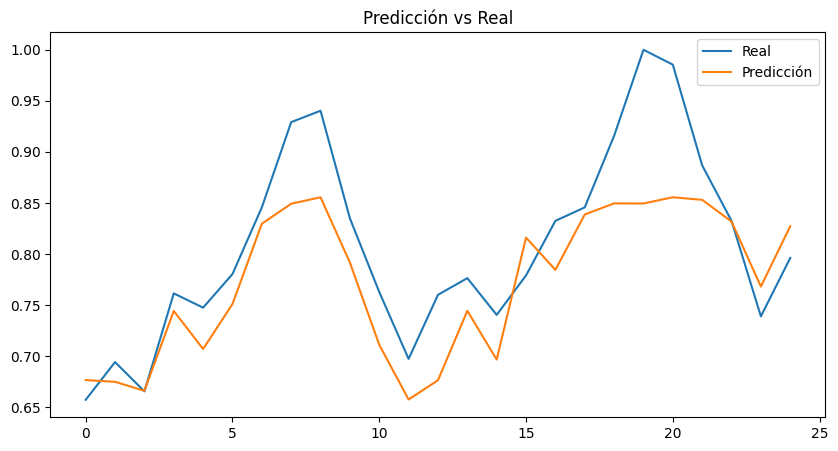

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(y_test, label='Real')
plt.plot(y_pred, label='Predicción')
plt.title('Predicción vs Real')
plt.legend()
plt.show()

Se ha entrenado un modelo de regresión Random Forest utilizando las variables generadas mediante time-delay embedding. Los resultados obtenidos muestran un buen ajuste del modelo, con valores bajos de RMSE y MAE. En la representación gráfica se observa que las predicciones siguen adecuadamente la tendencia de la serie real, aunque presentan cierta suavización en los picos, lo que indica que el modelo capta la dinámica general pero no reproduce completamente las variaciones extremas. En conjunto, el modelo ofrece un rendimiento adecuado para la predicción de la serie temporal.

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

modelo_lr = LinearRegression()

modelo_lr.fit(X_train, y_train)

y_pred_lr = modelo_lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"RMSE Linear Regression: {rmse_lr:.4f}")
print(f"MAE Linear Regression: {mae_lr:.4f}")

RMSE Linear Regression: 0.0311
MAE Linear Regression: 0.0266


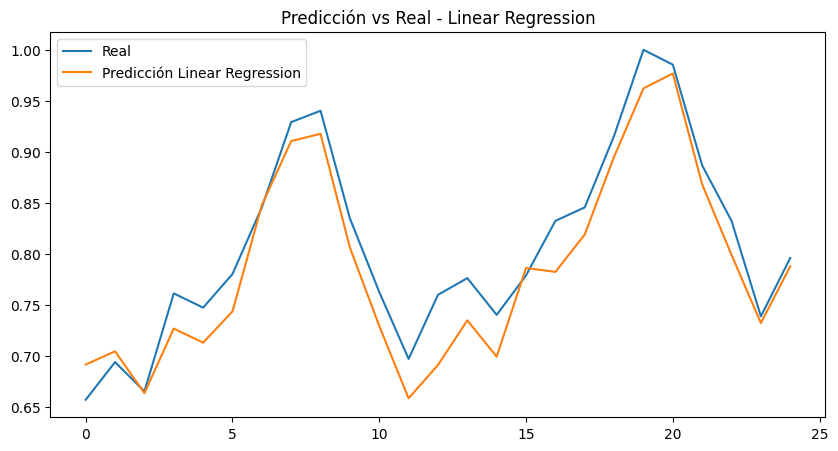

In [37]:
plt.figure(figsize=(10,5))
plt.plot(y_test, label='Real')
plt.plot(y_pred_lr, label='Predicción Linear Regression')
plt.title('Predicción vs Real - Linear Regression')
plt.legend()
plt.show()

Se ha comparado el modelo Random Forest con una regresión lineal para evaluar el impacto del tipo de modelo en la predicción. Los resultados muestran que la regresión lineal obtiene mejores métricas (RMSE y MAE más bajos), lo que indica un mejor ajuste a los datos. En la representación gráfica se observa que este modelo sigue más de cerca la serie real y reproduce mejor los picos. Esto sugiere que, dado que la serie presenta una estructura relativamente regular, un modelo lineal es suficiente para capturar su dinámica, resultando incluso más eficaz que modelos más complejos.

### Clasificación

In [38]:
from sklearn import svm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [39]:
def difference(series, interval=1):
    differenced_series = series.diff(periods=interval)
    return differenced_series


def create_time_delay_embedding_for_classification(data,
                                                   horizon,
                                                   final_lag,
                                                   column="y",
                                                   column_index=None):
    df_embedding = pd.DataFrame()
    df_embedding['y'] = data[column].copy()

    for i in range(horizon, final_lag + 1):
        df_embedding[f"lag_{i}"] = data[column].shift(i)

    for i in range(final_lag, df_embedding.shape[0]):
        if df_embedding["y"].iloc[i] > df_embedding[f"lag_{horizon}"].iloc[i]:
            df_embedding['y'].iloc[i] = 1
        else:
            df_embedding['y'].iloc[i] = 0

    df_embedding['y'].iloc[0:final_lag] = None

    if column_index is None:
        df_embedding.index = data.index
    else:
        df_embedding.index = data[column_index]

    return df_embedding


def timeseries_train_test_split(X, y, test_size):
    test_index = int(len(X) * (1 - test_size))

    X_train = X.iloc[:test_index]
    y_train = y.iloc[:test_index]
    X_test = X.iloc[test_index:]
    y_test = y.iloc[test_index:]

    return X_train, X_test, y_train, y_test


def compute_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f_one = f1_score(y_true, y_pred)

    print(f"Accuracy: {100*accuracy:.2f}%")
    print(f"Precision: {100*precision:.2f}%")
    print(f"Recall: {100*recall:.2f}%")
    print(f"F1 score: {100*f_one:.2f}%")

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f_one": f_one
    }


def plotModelResults(model, X_test, y_test):
    prediction = model.predict(X_test)
    compute_metrics(y_test, prediction)

    cm = confusion_matrix(y_test, prediction)
    ConfusionMatrixDisplay(confusion_matrix=cm).plot()

In [40]:
import pandas as pd

csv_path = 'AirPassengers.csv'

df = pd.read_csv(csv_path)

df['Fecha'] = df['Month']
df['NumerPasajeros'] = df['#Passengers']

In [43]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

minmax_scaler = MinMaxScaler()

df['LogNatural-NumeroPasajeros'] = np.log(df['NumerPasajeros'].values)

df['Min-Max-NumeroPasajeros'] = minmax_scaler.fit_transform(
    df['LogNatural-NumeroPasajeros'].values.reshape(-1, 1)
)

df['diff'] = df['Min-Max-NumeroPasajeros'].diff(periods=1)

In [44]:
horizon = 10
final_lag = 14

data = create_time_delay_embedding_for_classification(
    df,
    horizon=horizon,
    final_lag=final_lag,
    column="diff",
    column_index="Month"
)

y = data.dropna().y
X = data.dropna().drop(['y'], axis=1)

X_train, X_test, y_train, y_test = timeseries_train_test_split(X, y, test_size=0.3)

/tmp/ipykernel_5628/3696542519.py:19: FutureWarning:

ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


/tmp/ipykernel_5628/3696542519.py:21: FutureWarning:

ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained ass

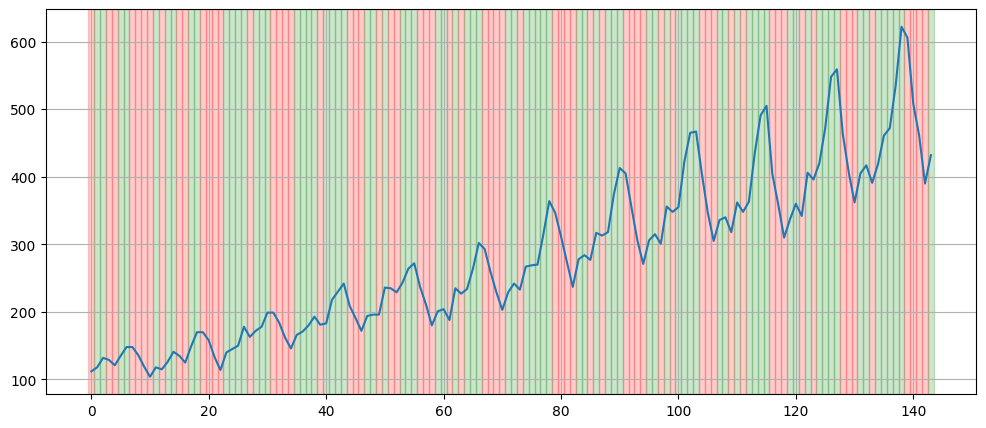

In [45]:
import matplotlib.pyplot as plt
import numpy as np

df['Clase'] = np.where(df['NumerPasajeros'].diff() > 0, 1, 0)

plt.figure(figsize=(12,5))

for i in range(len(df)):
    if df['Clase'].iloc[i] == 1:
        plt.axvspan(i-0.5, i+0.5, color='green', alpha=0.2)
    else:
        plt.axvspan(i-0.5, i+0.5, color='red', alpha=0.2)

plt.plot(df['NumerPasajeros'].values)

plt.grid()
plt.show()

### Procesamiento y preparación de datos

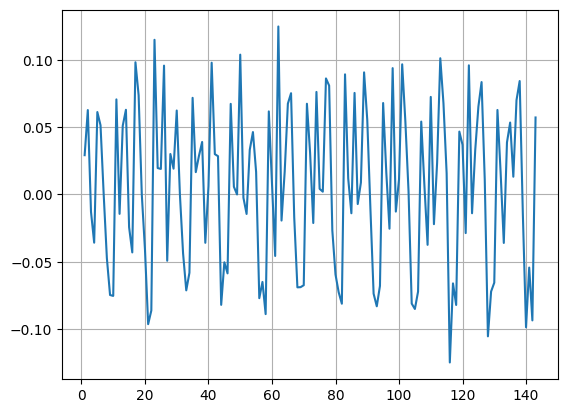

In [46]:
minmax_scaler = MinMaxScaler()

df['LogNatural-NumeroPasajeros'] = np.log(df['NumerPasajeros'].values)

df['Min-Max-NumeroPasajeros'] = minmax_scaler.fit_transform(
    df['LogNatural-NumeroPasajeros'].values.reshape(-1, 1)
)

df['diff'] = difference(df['Min-Max-NumeroPasajeros'], interval=1)

df['diff'].plot().grid()

### Entrenamiento SVM y Logistic Regression

------------------------------
SVM Results
Accuracy: 92.31%
Precision: 84.21%
Recall: 100.00%
F1 score: 91.43%


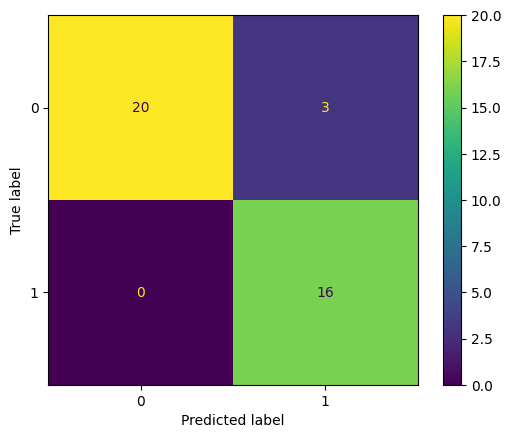

In [47]:
svm_clf = svm.SVC()
svm_clf.fit(X_train, y_train)

print("------------------------------")
print("SVM Results")
plotModelResults(svm_clf, X_test, y_test)

------------------------------
Logistic Regression Results
Accuracy: 92.31%
Precision: 84.21%
Recall: 100.00%
F1 score: 91.43%


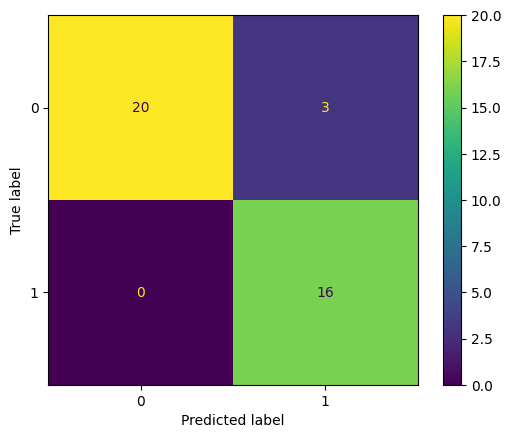

In [48]:
lr_clf = LogisticRegression(random_state=0)
lr_clf.fit(X_train, y_train)

print("------------------------------")
print("Logistic Regression Results")
plotModelResults(lr_clf, X_test, y_test)

Tanto el modelo SVM como el de Regresión Logística obtienen un rendimiento muy elevado en la tarea de clasificación, alcanzando una accuracy del 92.31%. Además, presentan un recall del 100%, lo que indica que son capaces de identificar correctamente todos los casos positivos. La matriz de confusión muestra únicamente tres errores de clasificación y ningún falso negativo, evidenciando que los modelos capturan adecuadamente la dinámica de la serie temporal tras el preprocesamiento aplicado. En conjunto, ambos modelos ofrecen resultados muy satisfactorios para la predicción de la dirección del cambio en la serie.